# Results

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, accuracy_score, auc, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.processing import augment_patient_and_cat_specific
from toolbox.results import Results_data_loading, ResultsROCAUC
from toolbox.visualization import plot_confusion_matrix_custom

warnings.filterwarnings("ignore")
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
mask.prints = False

In [2]:
# define number of group splits
cv = GroupKFold(n_splits=5)
parameter_type = "default"  # "tuned"
results_path = "results"

## Task 1 : healthy versus cancer


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 
Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}


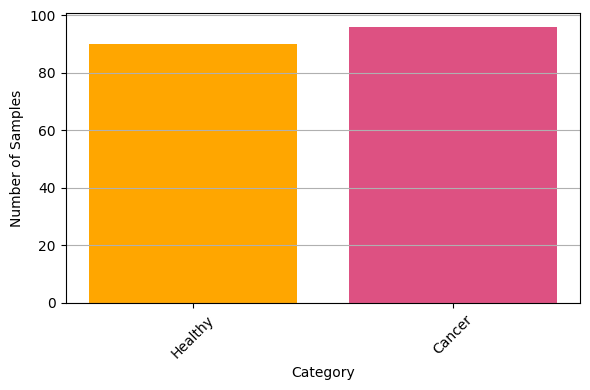


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


In [3]:
class_task = "healthy_vs_cancer"

# Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

In [4]:
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="rbf", C=10.0, probability=True)

# select freq and IIVV and shape data
X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [5]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.8279569892473119


In [6]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM_baseline.npz",
    model_type="Baseline",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.8527777777777777


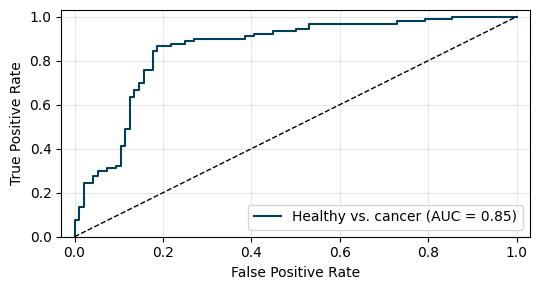

In [7]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_baseline.pdf",
)

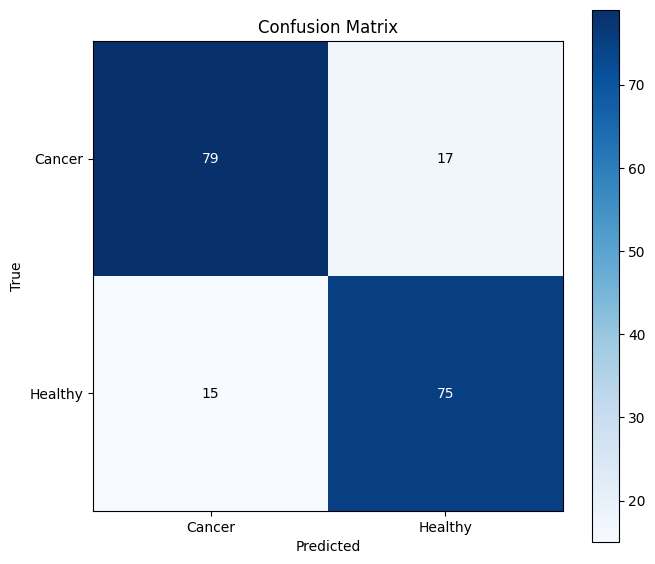

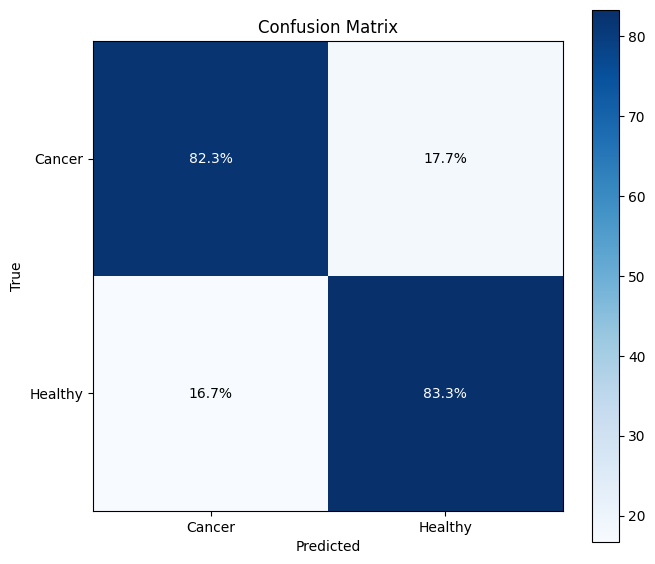

In [8]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=True
)

**RF**

In [9]:
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=800,
        max_depth=510,
        max_features="log2",
        min_samples_split=5,
        min_samples_leaf=1,
    )

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [10]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.8225806451612904


In [11]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF_baseline.npz",
    model_type="Baseline",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.8842592592592593


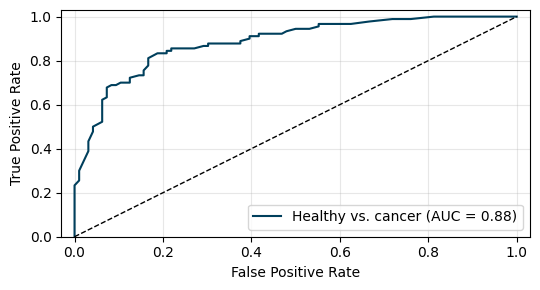

In [12]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF_baseline.pdf",
)

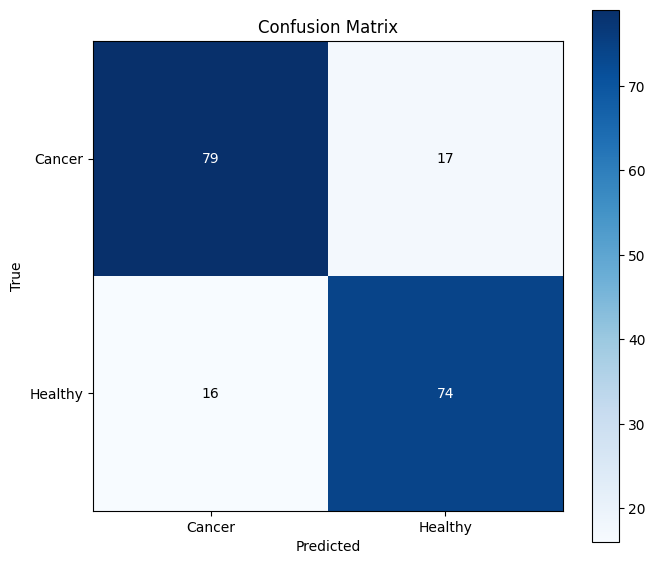

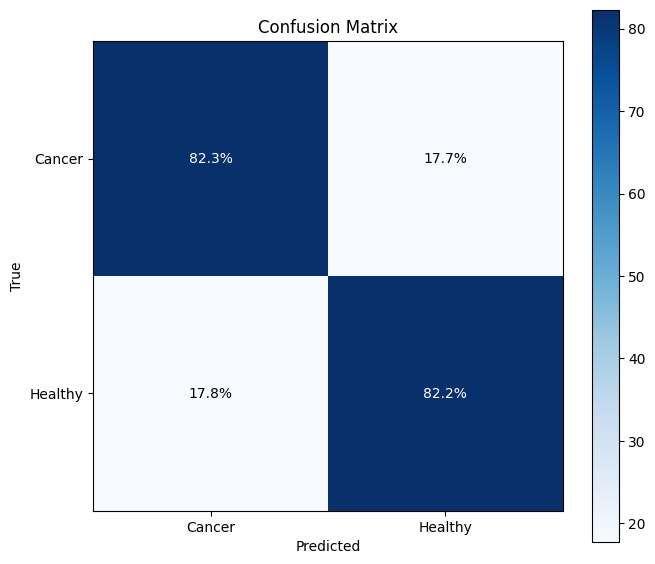

In [13]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=True
)

**LR**

In [14]:
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)
X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [15]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.7956989247311828


In [16]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR_baseline.npz",
    model_type="Baseline",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.8334490740740741


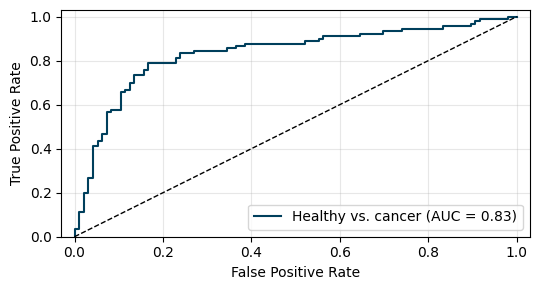

In [17]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_baseline.pdf",
)

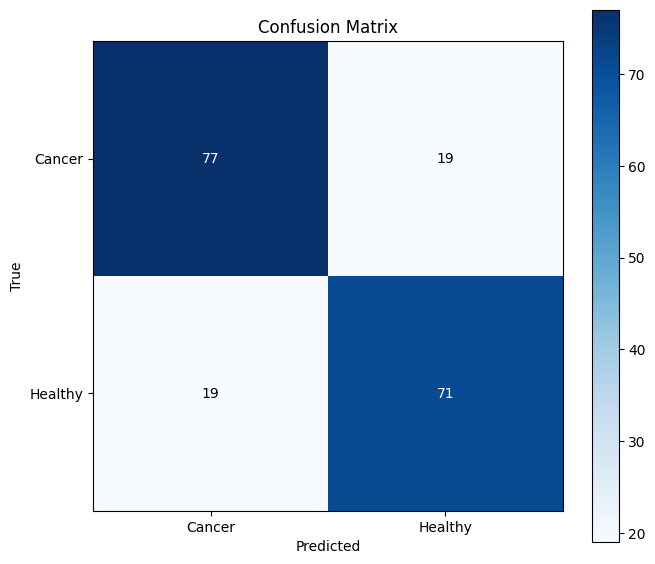

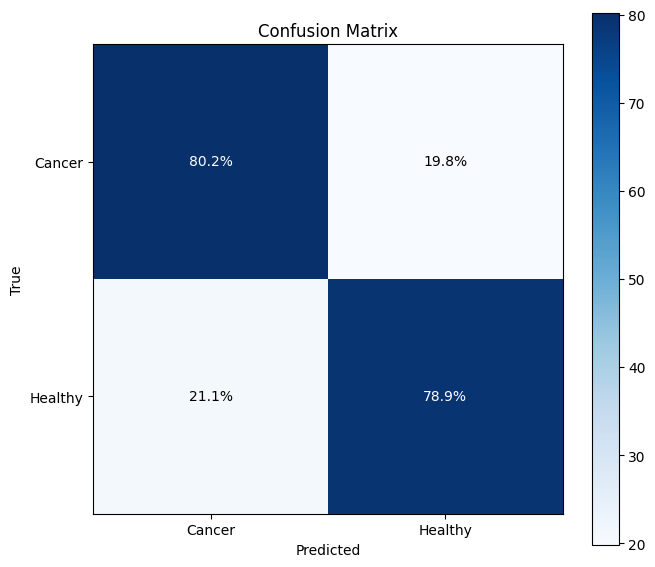

In [18]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=True
)

## Task 2 : Cancer vs. Low risk vs. High risk


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

High risk vs. Low risk

High risk: 125 entries
Low risk: 41 entries
Available cases: ['High risk' 'Low risk']
Coding: -> forward
{'High risk': [1, 0], 'Low risk': [0, 1]}


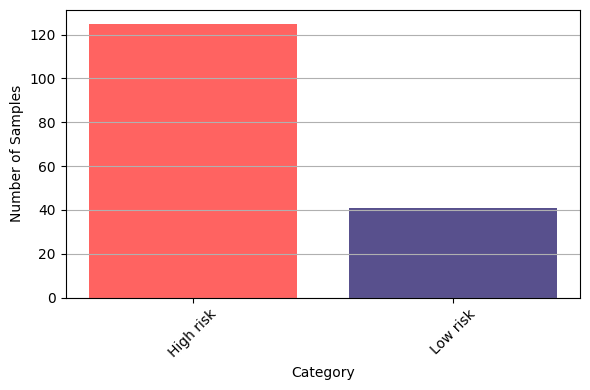


Inverse mapping: {(1, 0): 'High risk', (0, 1): 'Low risk'}
(166, 31, 7728) (166, 2) (166,)


In [19]:
class_task = "hr_vs_lr"

# Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

In [20]:
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="linear", C=0.001, probability=True, random_state=0)
X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(166, 239568)


In [21]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.7289156626506024


In [22]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM_baseline.npz",
    model_type="Baseline",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.6969756097560976


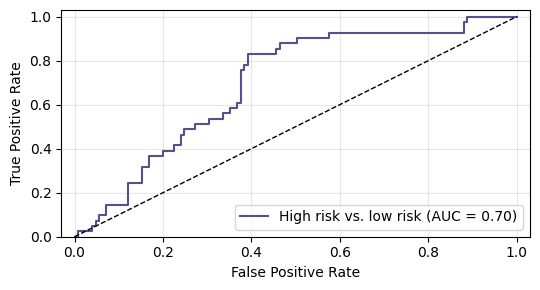

In [23]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_baseline.pdf",
)

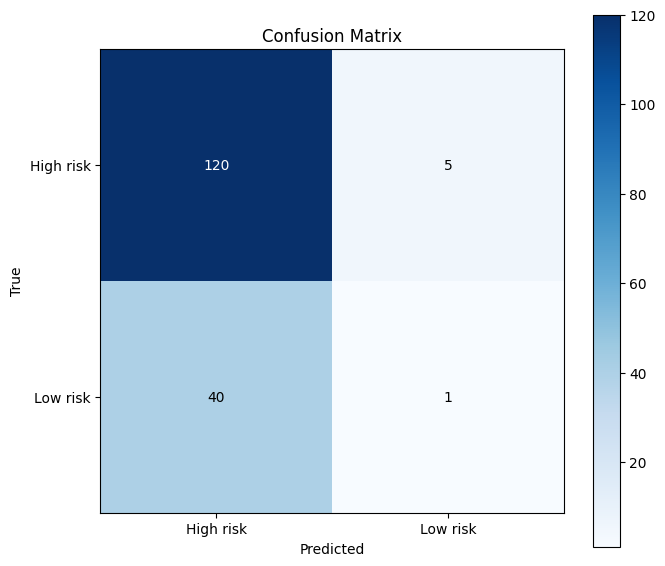

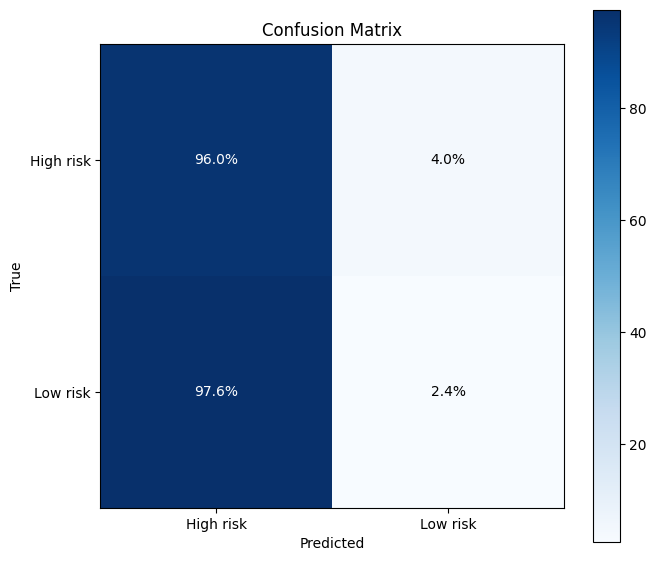

In [24]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["High risk", "Low risk"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["High risk", "Low risk"], normalize=True
)

**RF**

In [25]:
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=100,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=2,
    )

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(166, 239568)


In [26]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.7409638554216867


In [27]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF_baseline.npz",
    model_type="Baseline",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.6962926829268292


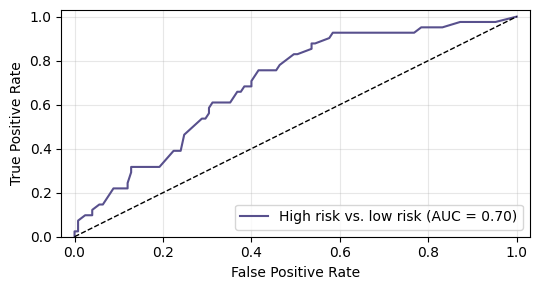

In [28]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF_baseline.pdf",
)

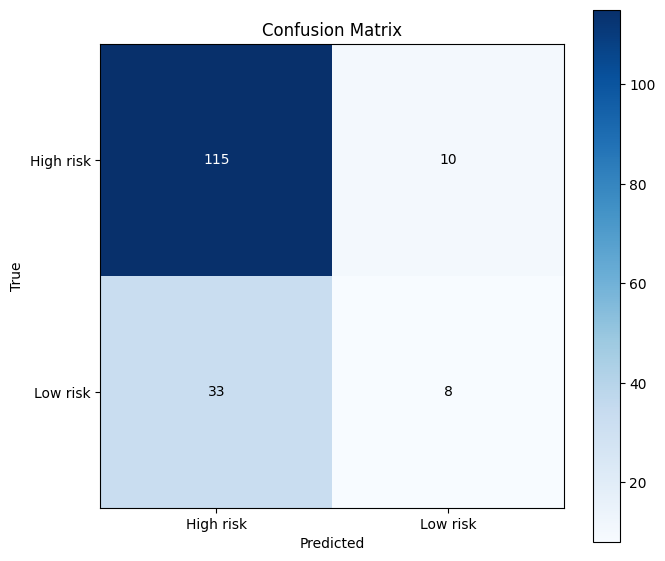

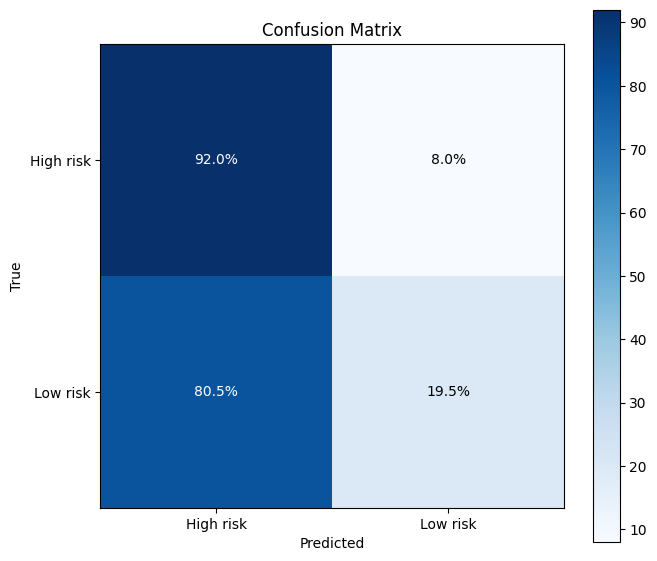

In [29]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["High risk", "Low risk"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["High risk", "Low risk"], normalize=True
)

**LR**

In [30]:
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(166, 239568)


In [31]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.6867469879518072


In [32]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR_baseline.npz",
    model_type="Baseline",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.6817560975609757


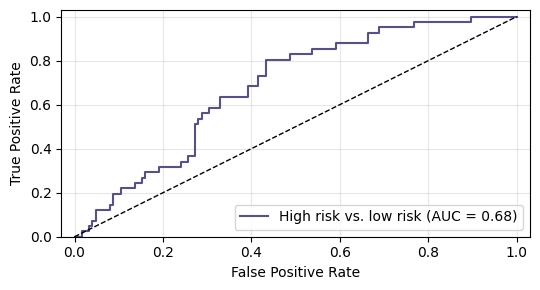

In [33]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_baseline.pdf",
)

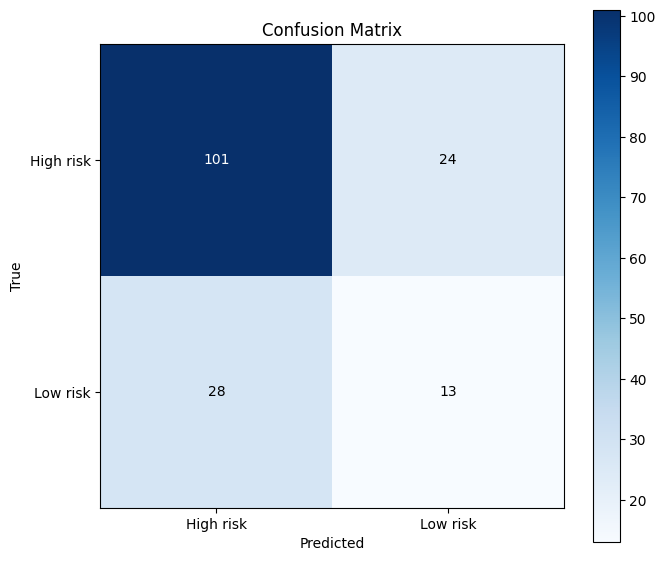

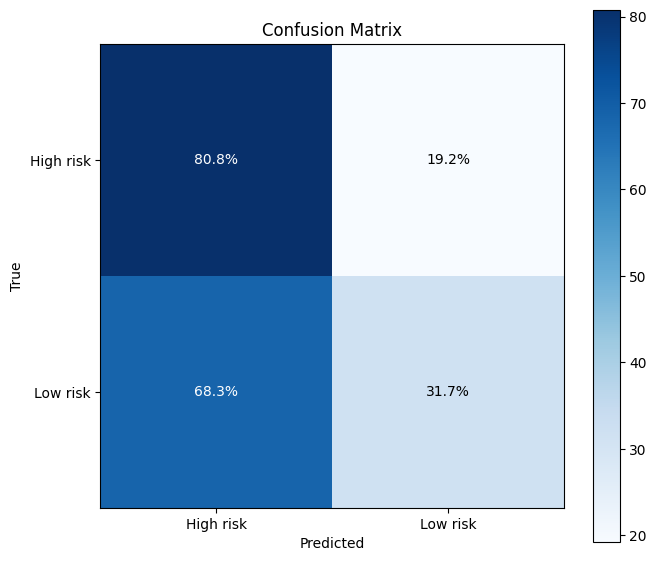

In [34]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["High risk", "Low risk"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["High risk", "Low risk"], normalize=True
)

## Task 3: Multiclass


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

MC

Healthy: 90 entries
Cancer: 96 entries
High-grade dysplasia: 29 entries
Non-malignant: 41 entries
Available cases: ['Cancer' 'Healthy' 'High-grade dysplasia' 'Non-malignant']
Coding: -> forward
{'Cancer': [1, 0, 0, 0], 'Healthy': [0, 1, 0, 0], 'High-grade dysplasia': [0, 0, 1, 0], 'Non-malignant': [0, 0, 0, 1]}


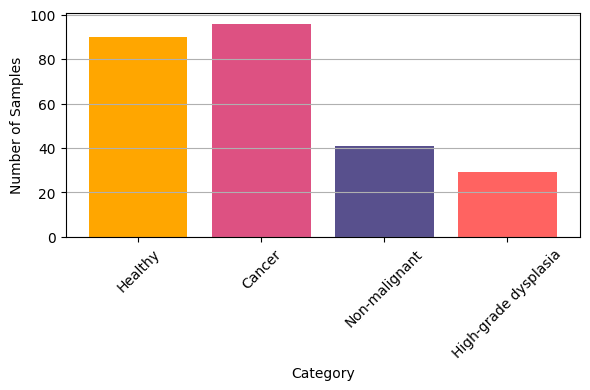


Inverse mapping: {(1, 0, 0, 0): 'Cancer', (0, 1, 0, 0): 'Healthy', (0, 0, 1, 0): 'High-grade dysplasia', (0, 0, 0, 1): 'Non-malignant'}
(256, 31, 7728) (256, 4) (256,)


In [35]:
class_task = "MC"

# Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)

**SVM**

In [36]:
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="rbf", C=100.0, probability=True, random_state=0)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(256, 239568)


In [37]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.58984375


In [38]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM_baseline.npz",
    model_type="Baseline",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.7754313151041665


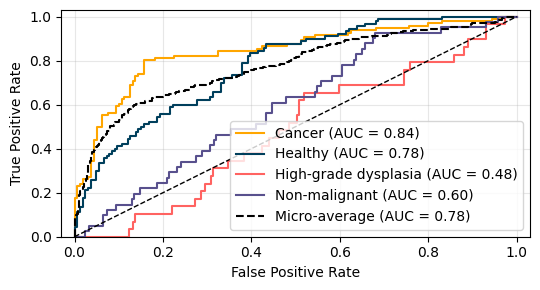

In [39]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_baseline.pdf",
)

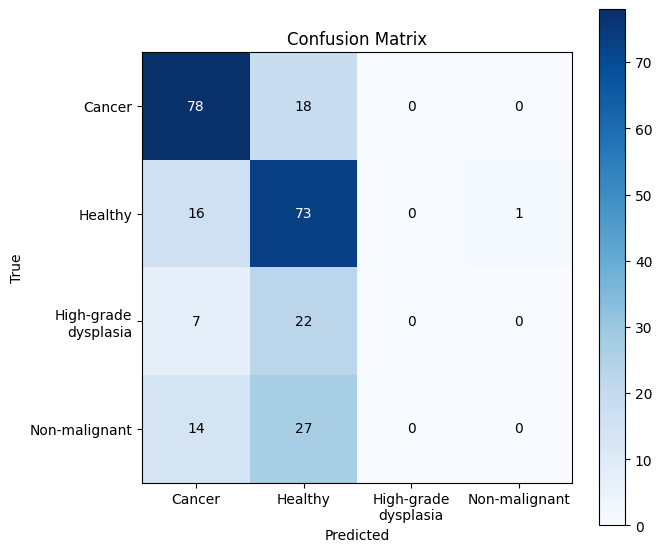

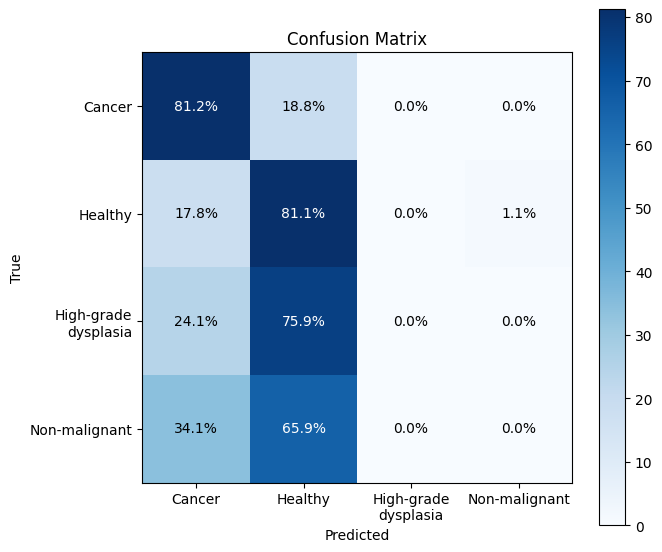

In [40]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
)

**RF**

In [41]:
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=800,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=1,
    )

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(256, 239568)


In [42]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.59375


In [43]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF_baseline.npz",
    model_type="Baseline",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.7954126993815105


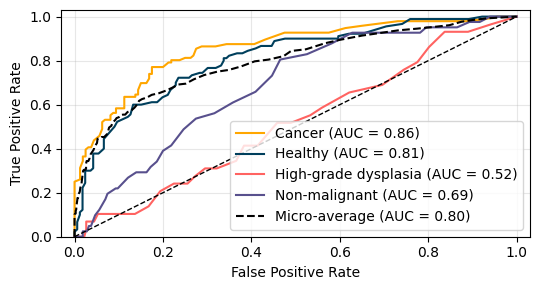

In [44]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF_baseline.pdf",
)

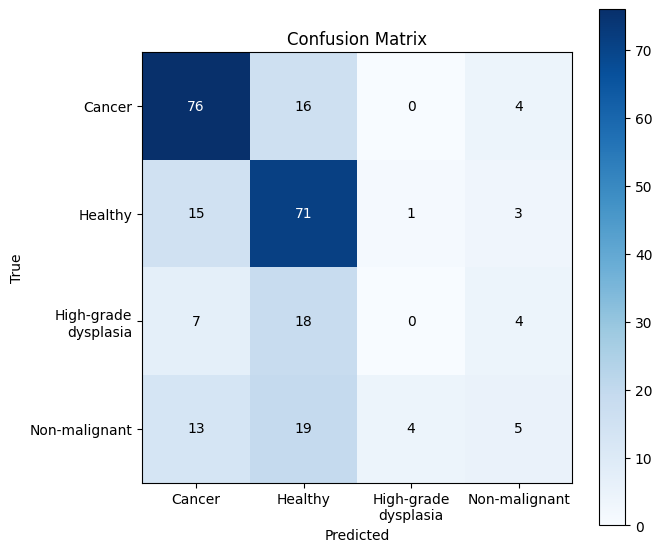

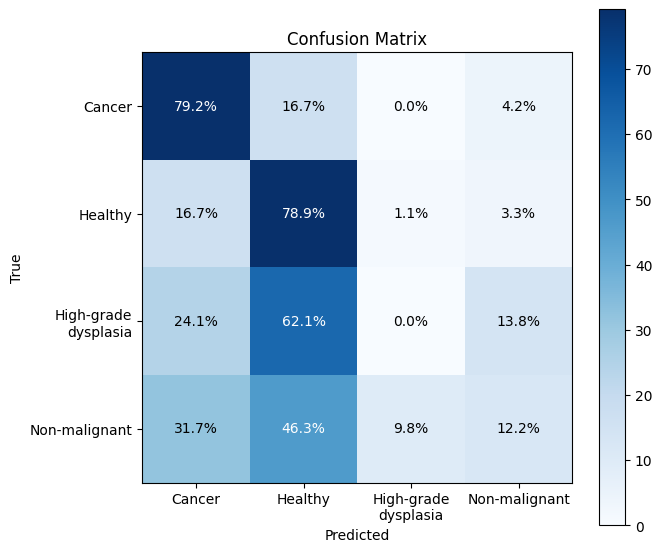

In [45]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
)

**LR**

In [46]:
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=1.0, max_iter=1000)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(256, 239568)


In [47]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.51171875


In [48]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR_baseline.npz",
    model_type="Baseline",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.7131551106770833


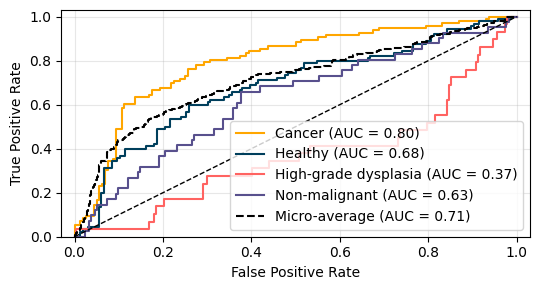

In [49]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_baseline.pdf",
)

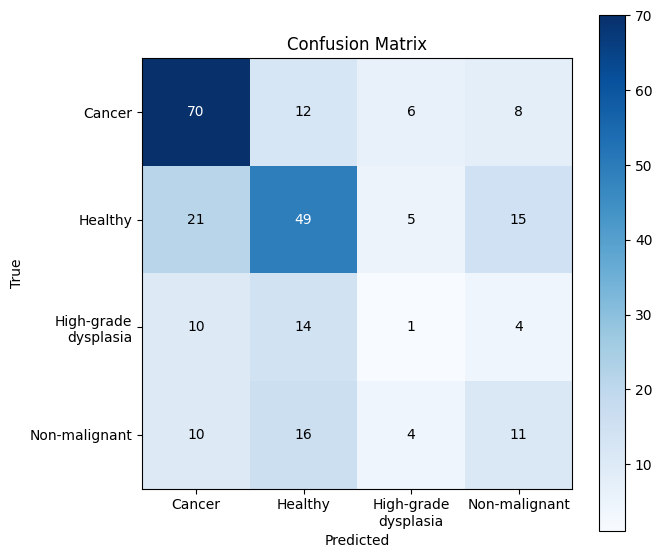

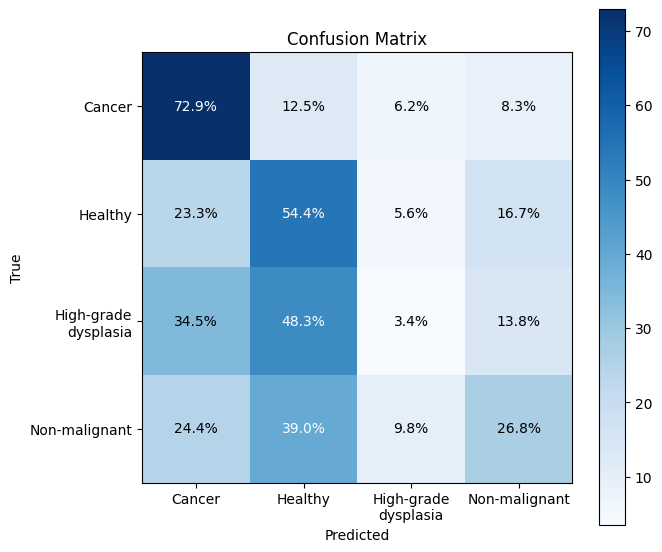

In [50]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
)

___